**LBF success-rate curves by env_id**

Run `wandb login` once before fetching curves.

In [6]:
from pathlib import Path
import os
import sys

MPLCONFIGDIR = Path("/tmp") / "pci_marl_matplotlib"
MPLCONFIGDIR.mkdir(parents=True, exist_ok=True)
os.environ["MPLCONFIGDIR"] = str(MPLCONFIGDIR)

FIGURES_DIR = Path.cwd()
if FIGURES_DIR.name != "figures" and (FIGURES_DIR / "figures").exists():
    FIGURES_DIR = FIGURES_DIR / "figures"
os.chdir(FIGURES_DIR)
sys.path.insert(0, str(FIGURES_DIR))
sys.path.insert(0, str(FIGURES_DIR.parent))

import importlib
import pandas as pd
import wandb_training_curves
import lbf_success_rate_plots
importlib.reload(wandb_training_curves)
importlib.reload(lbf_success_rate_plots)

from wandb_training_curves import (
    DEFAULT_ENTITY,
    build_plot_config,
    extract_final_performance,
    plot,
    plot_final_distribution,
    plot_horizontal_legend,
)
from lbf_success_rate_plots import (
    DEFAULT_CACHE_ROOT,
    DEFAULT_ENV_IDS,
    env_ids_from_checkpoints,
    fetch_lbf_env_curves,
    safe_name,
)

ENTITY = DEFAULT_ENTITY
CACHE_ROOT = DEFAULT_CACHE_ROOT
WINDOW = 20
LAST_N = 50
XLIM = (0, 2e6)
YLIM = (0, 1)
FETCH_FROM_WANDB = False

In [7]:
env_ids = list(DEFAULT_ENV_IDS)
# env_ids = env_ids_from_checkpoints()  # use this to include lr_bridge sweeps too
env_ids

['2s-8x8-2p-2f-coop', '2s-10x10-3p-3f', '2s-15x15-4p-3f', '2s-15x15-4p-5f']

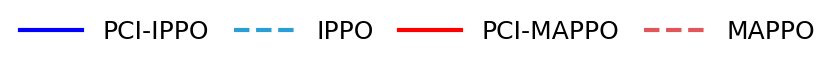

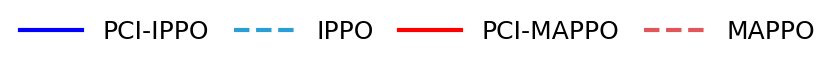

In [8]:
legend_config = build_plot_config("lbf", CACHE_ROOT / safe_name(env_ids[0]))
plot_horizontal_legend(
    legend_config,
    figsize=(5, 0.8),
)

In [9]:
if FETCH_FROM_WANDB:
    for env_id in env_ids:
        fetch_lbf_env_curves(
            env_id,
            cache_root=CACHE_ROOT,
            entity=ENTITY,
            state="finished",
        )


=== 2s-8x8-2p-2f-coop ===


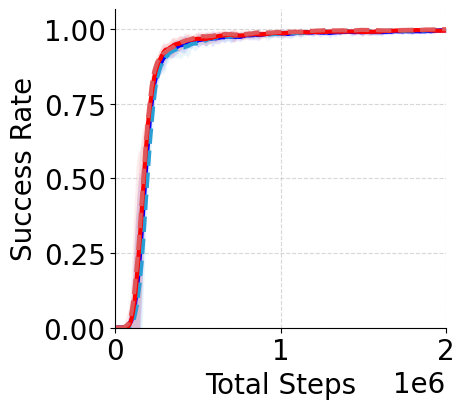

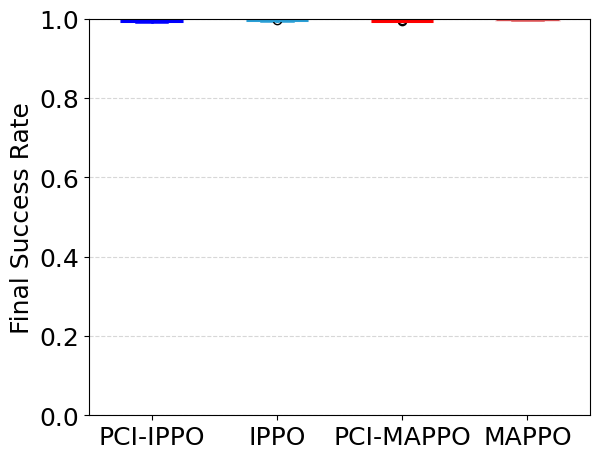


=== 2s-10x10-3p-3f ===


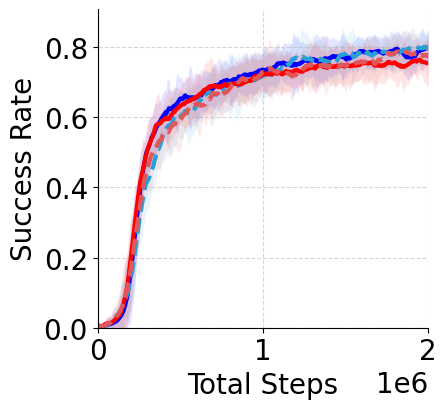

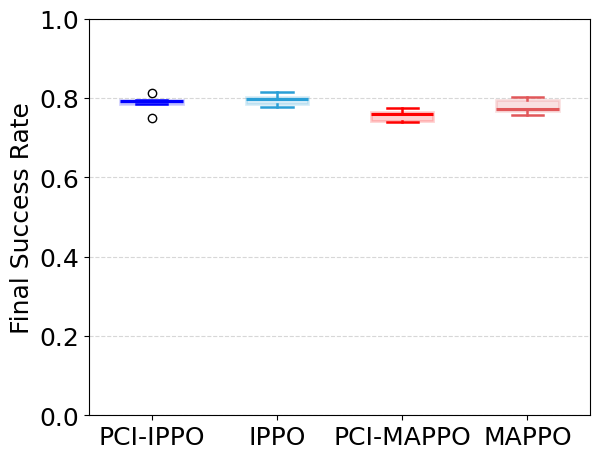


=== 2s-15x15-4p-3f ===


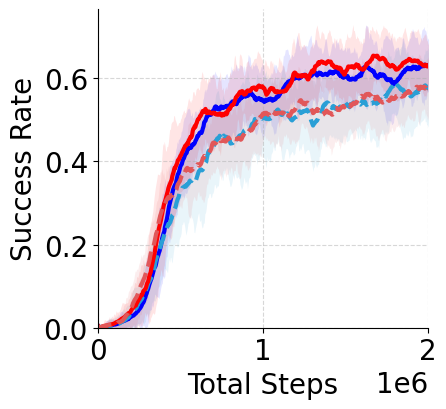

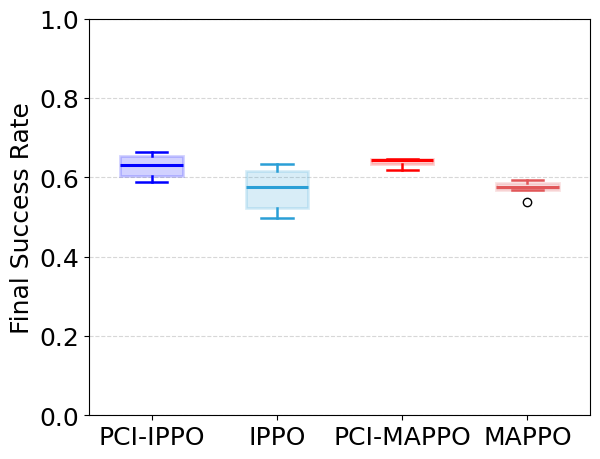


=== 2s-15x15-4p-5f ===


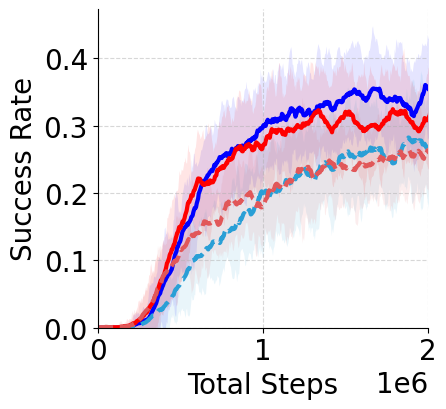

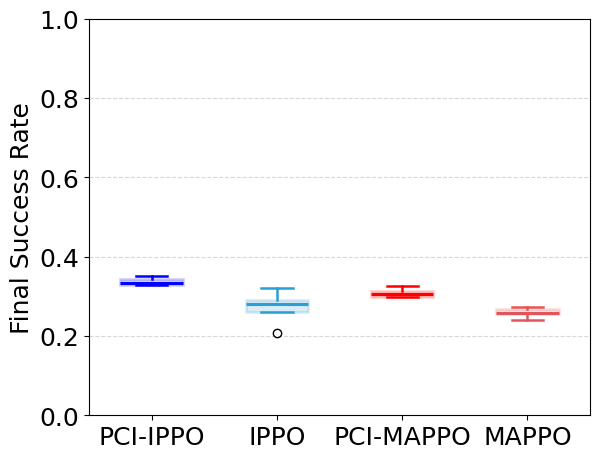

,env_id,algorithm,mean,std,n_seeds,min,max
0,2s-8x8-2p-2f-coop,PCI-IPPO,0.993663,0.001585,5,0.990879,0.995367
1,2s-8x8-2p-2f-coop,IPPO,0.995676,0.000856,4,0.994780,0.997080
2,2s-8x8-2p-2f-coop,PCI-MAPPO,0.994757,0.001227,5,0.993058,0.996854
3,2s-8x8-2p-2f-coop,MAPPO,0.997956,0.001171,5,0.996227,0.999292
4,2s-10x10-3p-3f,PCI-IPPO,0.785942,0.020782,5,0.748394,0.811593
5,2s-10x10-3p-3f,IPPO,0.794379,0.013042,5,0.777045,0.813558
6,2s-10x10-3p-3f,PCI-MAPPO,0.755841,0.013530,5,0.739095,0.774243
7,2s-10x10-3p-3f,MAPPO,0.778733,0.017067,5,0.757727,0.802000
8,2s-15x15-4p-3f,PCI-IPPO,0.627229,0.028826,5,0.587526,0.662314
9,2s-15x15-4p-3f,IPPO,0.568585,0.052598,5,0.496714,0.633296


In [10]:
summary_rows = []

for env_id in env_ids:
    print(f"\n=== {env_id} ===")
    plot_config = build_plot_config("lbf", CACHE_ROOT / safe_name(env_id))

    plot(
        plot_config,
        window_size=WINDOW,
        figsize=(5, 4.5),
        xlim=XLIM,
        # ylim=YLIM,
        mean_only=True,
        show_std_shading=True,
        uncertainty_metric="std",   # "std" or "iqr"
        std_shading_alpha=0.1,
    )

    plot_final_distribution(
        plot_config,
        window_size=WINDOW,
        last_n=LAST_N,
        figsize=(6.4, 5),
        ylim=YLIM,
        show_seed_points=False,
    )

    for row in extract_final_performance(plot_config, window_size=WINDOW, last_n=LAST_N):
        summary_rows.append({"env_id": env_id, **row})

pd.DataFrame(summary_rows)